Step 1: Import libraries

In [1]:
import os
import random
import copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Device:", device)

PyTorch version: 2.14.0+cpu
Device: cpu


Step 2: Load processed data

In [2]:
output_dir = Path("../Outputs")

X_train = np.load(output_dir / "X_train.npy")
X_val = np.load(output_dir / "X_val.npy")

y_train = np.load(output_dir / "y_train.npy")
y_val = np.load(output_dir / "y_val.npy")

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)

print("Training class distribution:")
print(np.unique(y_train, return_counts=True))

Training: (31647, 50) (31647,)
Validation: (6782, 50) (6782,)
Training class distribution:
(array([0, 1]), array([27945,  3702]))


Step 3: Convert data to PyTorch tensors

In [3]:
X_train_tensor = torch.tensor(
    X_train, dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train, dtype=torch.float32
).reshape(-1, 1)

X_val_tensor = torch.tensor(
    X_val, dtype=torch.float32
)

y_val_tensor = torch.tensor(
    y_val, dtype=torch.float32
).reshape(-1, 1)

train_dataset = TensorDataset(
    X_train_tensor, y_train_tensor
)

val_dataset = TensorDataset(
    X_val_tensor, y_val_tensor
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

Training samples: 31647
Validation samples: 6782


Step 4: Define MLP architecture

In [4]:
class BankMarketingMLP(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)


input_size = X_train.shape[1]

print("Input features:", input_size)

Input features: 50


Step 5: Create evaluation function

In [5]:
def evaluate_model(model, data_loader, criterion):

    model.eval()

    total_loss = 0
    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for inputs, labels in data_loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            logits = model(inputs)

            loss = criterion(logits, labels)

            total_loss += loss.item() * inputs.size(0)

            probabilities = torch.sigmoid(logits)

            predictions = (
                probabilities >= 0.5
            ).int()

            all_labels.extend(
                labels.cpu().numpy().ravel()
            )

            all_predictions.extend(
                predictions.cpu().numpy().ravel()
            )

    avg_loss = total_loss / len(data_loader.dataset)

    accuracy = accuracy_score(
        all_labels, all_predictions
    )

    precision = precision_score(
        all_labels, all_predictions,
        zero_division=0
    )

    recall = recall_score(
        all_labels, all_predictions,
        zero_division=0
    )

    f1 = f1_score(
        all_labels, all_predictions,
        zero_division=0
    )

    return {
        "loss": avg_loss,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

Step 6: Create training function

In [6]:
def train_model(
    experiment_name,
    learning_rate,
    batch_size,
    epochs=30
):

    # Reset seed for reproducibility
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    model = BankMarketingMLP(input_size).to(device)

    criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    generator = torch.Generator()
    generator.manual_seed(SEED)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        generator=generator
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    history = []

    best_f1 = -1.0
    best_val_loss = float("inf")
    best_epoch = 0
    best_state = None

    for epoch in range(epochs):

        model.train()

        for inputs, labels in train_loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            logits = model(inputs)

            loss = criterion(logits, labels)

            loss.backward()

            optimizer.step()

        # Calculate training and validation metrics
        train_metrics = evaluate_model(
            model, train_loader, criterion
        )

        val_metrics = evaluate_model(
            model, val_loader, criterion
        )

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_metrics["loss"],
            "val_loss": val_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "val_accuracy": val_metrics["accuracy"],
            "val_precision": val_metrics["precision"],
            "val_recall": val_metrics["recall"],
            "val_f1": val_metrics["f1"]
        })

        # Select best epoch using validation F1
        if (
            val_metrics["f1"] > best_f1
            or (
                val_metrics["f1"] == best_f1
                and val_metrics["loss"] < best_val_loss
            )
        ):

            best_f1 = val_metrics["f1"]
            best_val_loss = val_metrics["loss"]
            best_epoch = epoch + 1

            best_state = copy.deepcopy(
                model.state_dict()
            )

        print(
            f"{experiment_name} | "
            f"Epoch {epoch + 1:02d}/{epochs} | "
            f"Train Loss: {train_metrics['loss']:.4f} | "
            f"Val Loss: {val_metrics['loss']:.4f} | "
            f"Train Acc: {train_metrics['accuracy']:.4f} | "
            f"Val Acc: {val_metrics['accuracy']:.4f} | "
            f"Val F1: {val_metrics['f1']:.4f}"
        )

    model.load_state_dict(best_state)

    return {
        "name": experiment_name,
        "model": model,
        "history": pd.DataFrame(history),
        "best_epoch": best_epoch,
        "best_f1": best_f1,
        "learning_rate": learning_rate,
        "batch_size": batch_size
    }

Step 7: Train baseline model

In [7]:
baseline = train_model(
    experiment_name="Baseline",
    learning_rate=0.001,
    batch_size=32,
    epochs=30
)

print("\nBest Baseline Epoch:", baseline["best_epoch"])
print("Best Validation F1:", baseline["best_f1"])

Baseline | Epoch 01/30 | Train Loss: 0.2987 | Val Loss: 0.2954 | Train Acc: 0.8918 | Val Acc: 0.8941 | Val F1: 0.3401
Baseline | Epoch 02/30 | Train Loss: 0.2891 | Val Loss: 0.2890 | Train Acc: 0.8928 | Val Acc: 0.8962 | Val F1: 0.3680
Baseline | Epoch 03/30 | Train Loss: 0.2857 | Val Loss: 0.2872 | Train Acc: 0.8936 | Val Acc: 0.8981 | Val F1: 0.3560
Baseline | Epoch 04/30 | Train Loss: 0.2835 | Val Loss: 0.2855 | Train Acc: 0.8948 | Val Acc: 0.8971 | Val F1: 0.3596
Baseline | Epoch 05/30 | Train Loss: 0.2811 | Val Loss: 0.2871 | Train Acc: 0.8959 | Val Acc: 0.8955 | Val F1: 0.4145
Baseline | Epoch 06/30 | Train Loss: 0.2791 | Val Loss: 0.2870 | Train Acc: 0.8961 | Val Acc: 0.8947 | Val F1: 0.2945
Baseline | Epoch 07/30 | Train Loss: 0.2762 | Val Loss: 0.2844 | Train Acc: 0.8977 | Val Acc: 0.8969 | Val F1: 0.3387
Baseline | Epoch 08/30 | Train Loss: 0.2732 | Val Loss: 0.2852 | Train Acc: 0.8993 | Val Acc: 0.8975 | Val F1: 0.3789
Baseline | Epoch 09/30 | Train Loss: 0.2740 | Val Loss: 

Step 8: Experiment 1 (change learning rate)

In [8]:
experiment1 = train_model(
    experiment_name="Experiment 1",
    learning_rate=0.0005,
    batch_size=32,
    epochs=30
)

print("\nBest Experiment 1 Epoch:", experiment1["best_epoch"])
print("Best Validation F1:", experiment1["best_f1"])

Experiment 1 | Epoch 01/30 | Train Loss: 0.3006 | Val Loss: 0.2968 | Train Acc: 0.8919 | Val Acc: 0.8937 | Val F1: 0.3243
Experiment 1 | Epoch 02/30 | Train Loss: 0.2924 | Val Loss: 0.2909 | Train Acc: 0.8930 | Val Acc: 0.8944 | Val F1: 0.3233
Experiment 1 | Epoch 03/30 | Train Loss: 0.2895 | Val Loss: 0.2890 | Train Acc: 0.8935 | Val Acc: 0.8955 | Val F1: 0.3477
Experiment 1 | Epoch 04/30 | Train Loss: 0.2875 | Val Loss: 0.2869 | Train Acc: 0.8934 | Val Acc: 0.8958 | Val F1: 0.3386
Experiment 1 | Epoch 05/30 | Train Loss: 0.2847 | Val Loss: 0.2867 | Train Acc: 0.8947 | Val Acc: 0.8962 | Val F1: 0.3962
Experiment 1 | Epoch 06/30 | Train Loss: 0.2832 | Val Loss: 0.2859 | Train Acc: 0.8949 | Val Acc: 0.8962 | Val F1: 0.3282
Experiment 1 | Epoch 07/30 | Train Loss: 0.2808 | Val Loss: 0.2842 | Train Acc: 0.8958 | Val Acc: 0.8965 | Val F1: 0.3512
Experiment 1 | Epoch 08/30 | Train Loss: 0.2791 | Val Loss: 0.2846 | Train Acc: 0.8966 | Val Acc: 0.8969 | Val F1: 0.3708
Experiment 1 | Epoch 09/

Step 9: Experiment 2 (change batch size)

In [9]:
experiment2 = train_model(
    experiment_name="Experiment 2",
    learning_rate=0.001,
    batch_size=64,
    epochs=30
)

print("\nBest Experiment 2 Epoch:", experiment2["best_epoch"])
print("Best Validation F1:", experiment2["best_f1"])

Experiment 2 | Epoch 01/30 | Train Loss: 0.3007 | Val Loss: 0.2972 | Train Acc: 0.8910 | Val Acc: 0.8938 | Val F1: 0.3407
Experiment 2 | Epoch 02/30 | Train Loss: 0.2911 | Val Loss: 0.2900 | Train Acc: 0.8930 | Val Acc: 0.8953 | Val F1: 0.3462
Experiment 2 | Epoch 03/30 | Train Loss: 0.2885 | Val Loss: 0.2885 | Train Acc: 0.8939 | Val Acc: 0.8981 | Val F1: 0.3678
Experiment 2 | Epoch 04/30 | Train Loss: 0.2856 | Val Loss: 0.2860 | Train Acc: 0.8941 | Val Acc: 0.8953 | Val F1: 0.3450
Experiment 2 | Epoch 05/30 | Train Loss: 0.2826 | Val Loss: 0.2856 | Train Acc: 0.8953 | Val Acc: 0.8969 | Val F1: 0.4021
Experiment 2 | Epoch 06/30 | Train Loss: 0.2817 | Val Loss: 0.2863 | Train Acc: 0.8959 | Val Acc: 0.8959 | Val F1: 0.3390
Experiment 2 | Epoch 07/30 | Train Loss: 0.2790 | Val Loss: 0.2839 | Train Acc: 0.8970 | Val Acc: 0.8969 | Val F1: 0.3498
Experiment 2 | Epoch 08/30 | Train Loss: 0.2762 | Val Loss: 0.2840 | Train Acc: 0.8983 | Val Acc: 0.8988 | Val F1: 0.3809
Experiment 2 | Epoch 09/

Step 10: Compare three experiments

In [10]:
experiments = [baseline, experiment1, experiment2]

comparison = []

for exp in experiments:

    best_row = exp["history"].loc[
        exp["history"]["epoch"] == exp["best_epoch"]
    ].iloc[0]

    comparison.append({
        "Experiment": exp["name"],
        "Learning Rate": exp["learning_rate"],
        "Batch Size": exp["batch_size"],
        "Best Epoch": exp["best_epoch"],
        "Val Loss": best_row["val_loss"],
        "Val Accuracy": best_row["val_accuracy"],
        "Val Precision": best_row["val_precision"],
        "Val Recall": best_row["val_recall"],
        "Val F1": best_row["val_f1"]
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(4))

,Experiment,Learning Rate,Batch Size,Best Epoch,Val Loss,Val Accuracy,Val Precision,Val Recall,Val F1
0,Baseline,0.0010,32,5,0.2871,0.8955,0.6019,0.3161,0.4145
1,Experiment 1,0.0005,32,30,0.2972,0.8927,0.5665,0.3539,0.4357
2,Experiment 2,0.0010,64,13,0.2887,0.8972,0.6198,0.3161,0.4187


Step 11: Create training and validation curves

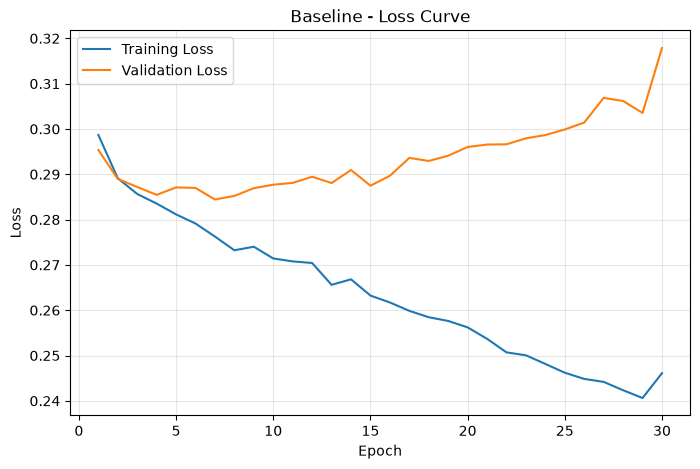

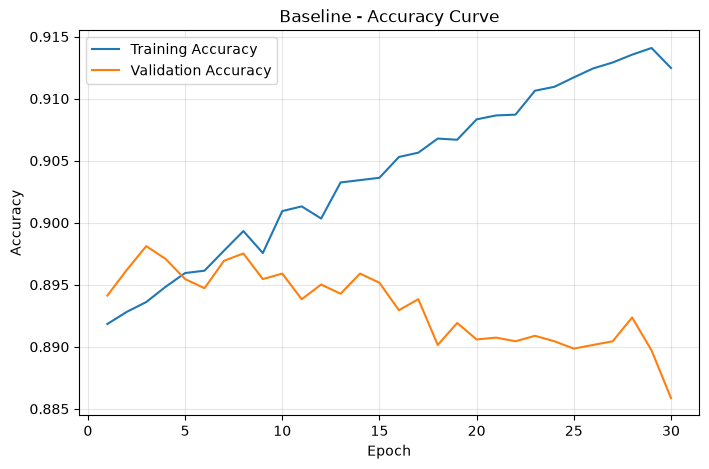

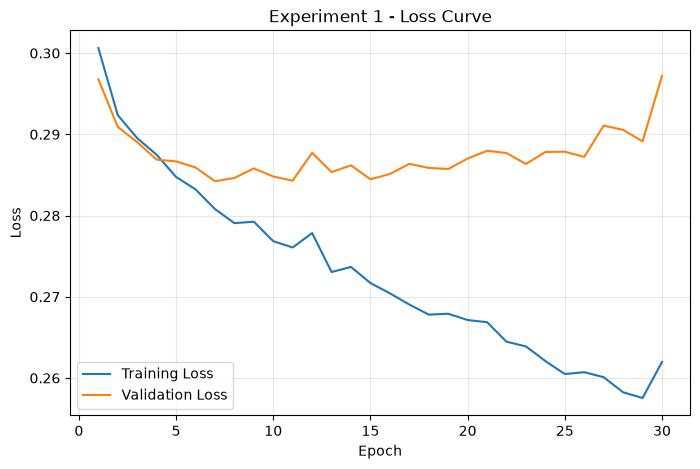

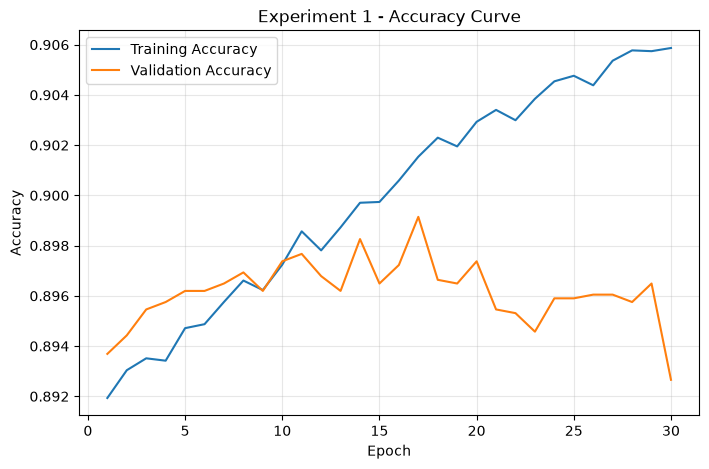

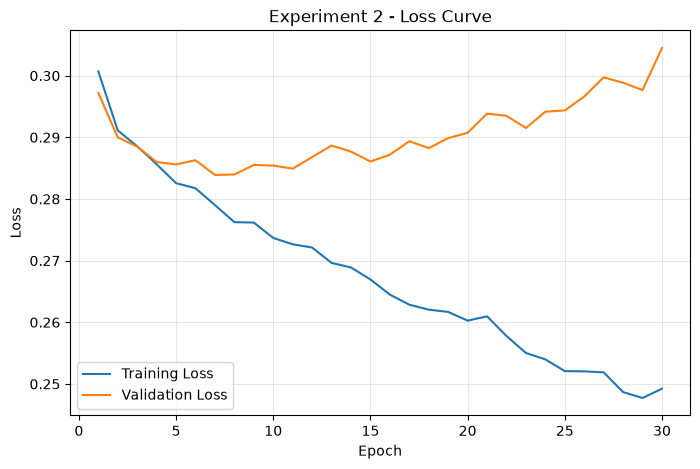

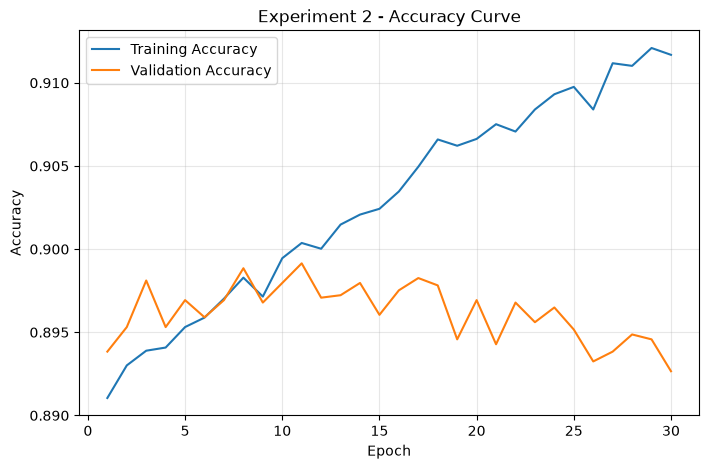

In [11]:
graph_dir = Path("../Outputs/Task4_Graphs")
graph_dir.mkdir(parents=True, exist_ok=True)

for exp in experiments:

    history = exp["history"]
    name = exp["name"].replace(" ", "_").lower()

    # Loss Curve
    plt.figure(figsize=(8, 5))

    plt.plot(
        history["epoch"],
        history["train_loss"],
        label="Training Loss"
    )

    plt.plot(
        history["epoch"],
        history["val_loss"],
        label="Validation Loss"
    )

    plt.title(f"{exp['name']} - Loss Curve")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(alpha=0.3)

    plt.savefig(
        graph_dir / f"{name}_loss.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    # Accuracy Curve
    plt.figure(figsize=(8, 5))

    plt.plot(
        history["epoch"],
        history["train_accuracy"],
        label="Training Accuracy"
    )

    plt.plot(
        history["epoch"],
        history["val_accuracy"],
        label="Validation Accuracy"
    )

    plt.title(f"{exp['name']} - Accuracy Curve")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(alpha=0.3)

    plt.savefig(
        graph_dir / f"{name}_accuracy.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

Step 12: Select and save best model

In [12]:
best_experiment = max(
    experiments,
    key=lambda exp: exp["best_f1"]
)

best_model = best_experiment["model"]

print("Best Experiment:", best_experiment["name"])
print("Best Epoch:", best_experiment["best_epoch"])
print("Best Validation F1:", best_experiment["best_f1"])

Best Experiment: Experiment 1
Best Epoch: 30
Best Validation F1: 0.4356589147286822


In [13]:
model_dir = Path("../Model")
model_dir.mkdir(parents=True, exist_ok=True)

torch.save({
    "model_state_dict": best_model.state_dict(),
    "input_size": input_size,
    "hidden_layers": [64, 32],
    "best_experiment": best_experiment["name"],
    "best_epoch": best_experiment["best_epoch"],
    "validation_f1": best_experiment["best_f1"],
    "classification_threshold": 0.5
}, model_dir / "best_mlp_model.pth")

comparison_df.to_csv(
    "../Outputs/task4_experiment_comparison.csv",
    index=False
)

for exp in experiments:
    name = exp["name"].replace(" ", "_").lower()

    exp["history"].to_csv(
        f"../Outputs/{name}_history.csv",
        index=False
    )

print("Best model and experiment results saved successfully!")

Best model and experiment results saved successfully!
